In [5]:
# 과거 데이터로 실험
#df_jeonju['날짜'].dt.date.value_counts().sort_index()

날짜
2020-06-01    1
2020-06-02    1
2020-06-03    1
2020-06-04    1
2020-06-05    1
2020-06-06    1
2020-06-07    1
2020-06-08    1
2020-06-09    1
2020-06-10    1
2020-06-11    1
2020-06-12    1
2020-06-13    1
2020-06-14    1
2020-06-15    1
2020-06-16    1
2020-06-17    1
2020-06-18    1
2020-06-19    1
2020-06-20    1
2020-06-21    1
2020-06-22    1
2020-06-23    1
2020-06-24    1
2020-06-25    1
2020-06-26    1
2020-06-27    1
2020-06-28    1
2020-06-29    1
2020-06-30    1
Name: count, dtype: int64

In [21]:
#print("내일 지수 분포:\n", df_jeonju['내일'].value_counts(dropna=False))
#print("\n모레 지수 분포:\n", df_jeonju['모레'].value_counts(dropna=False))

내일 지수 분포:
 내일
0    30
Name: count, dtype: int64

모레 지수 분포:
 모레
0    30
Name: count, dtype: int64


In [27]:
#과거 데이터 테스트
#print(df['날짜'].dt.date.unique())

[datetime.date(2020, 6, 1) datetime.date(2020, 6, 2)
 datetime.date(2020, 6, 3) datetime.date(2020, 6, 4)
 datetime.date(2020, 6, 5) datetime.date(2020, 6, 6)
 datetime.date(2020, 6, 7) datetime.date(2020, 6, 8)
 datetime.date(2020, 6, 9) datetime.date(2020, 6, 10)
 datetime.date(2020, 6, 11) datetime.date(2020, 6, 12)
 datetime.date(2020, 6, 13) datetime.date(2020, 6, 14)
 datetime.date(2020, 6, 15) datetime.date(2020, 6, 16)
 datetime.date(2020, 6, 17) datetime.date(2020, 6, 18)
 datetime.date(2020, 6, 19) datetime.date(2020, 6, 20)
 datetime.date(2020, 6, 21) datetime.date(2020, 6, 22)
 datetime.date(2020, 6, 23) datetime.date(2020, 6, 24)
 datetime.date(2020, 6, 25) datetime.date(2020, 6, 26)
 datetime.date(2020, 6, 27) datetime.date(2020, 6, 28)
 datetime.date(2020, 6, 29) datetime.date(2020, 6, 30)]


[1] 날짜별 평균 꽃가루 지수:
             날짜    일별평균지수
0   2025-05-01  1.181250
1   2025-05-02  0.721875
2   2025-05-03  1.118750
3   2025-05-04  0.759375
4   2025-05-05  0.390625
5   2025-05-06  0.353125
6   2025-05-07  0.615625
7   2025-05-08  0.209375
8   2025-05-09  0.031250
9   2025-05-10  0.118750
10  2025-05-11  0.056250
11  2025-05-12  0.146875
12  2025-05-13  0.221875

[2] 위험 등급별 빈도수:
    등급   빈도수
0  낮음  2454
1  높음   190
2  보통  1516

 [3] 연속 고위험일 탐지 결과:
                        날짜   내일
2506  2025-05-01 18:00:00  2.0
2498  2025-05-01 18:00:00  2.0
2496  2025-05-01 18:00:00  2.0
2495  2025-05-01 18:00:00  2.0
2494  2025-05-01 18:00:00  2.0
2525  2025-05-01 18:00:00  2.0
2524  2025-05-01 18:00:00  2.0
2514  2025-05-01 18:00:00  2.0
2513  2025-05-01 18:00:00  2.0
2512  2025-05-01 18:00:00  2.0
2587  2025-05-01 18:00:00  2.0
2459  2025-05-01 18:00:00  2.0
2453  2025-05-01 18:00:00  2.0
2457  2025-05-01 18:00:00  2.0
2473  2025-05-01 18:00:00  2.0
10186 2025-05-03 18:00:00  2.0
10182 2025-05-0

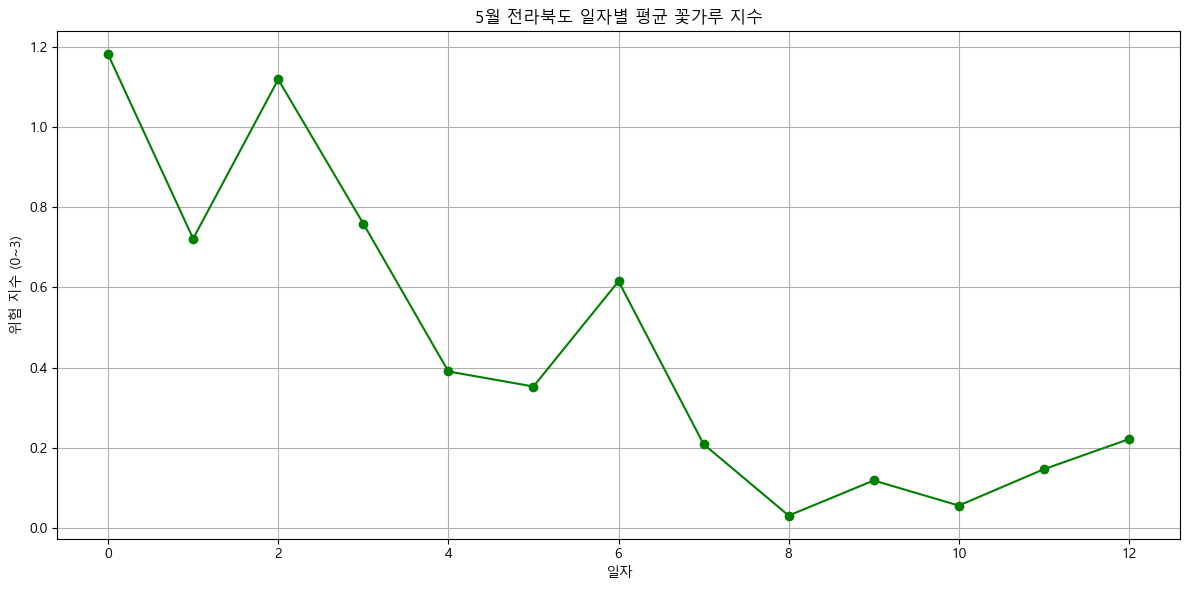

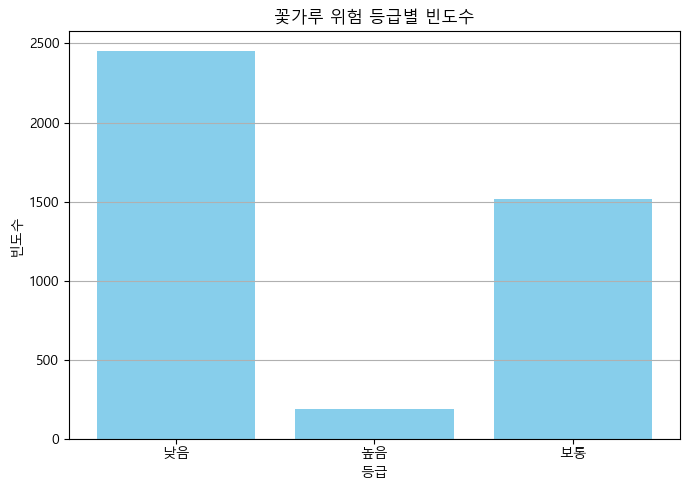

In [112]:
import pandas as pd               # 판다스 불러기기
import matplotlib.pyplot as plt   # 시각화
import matplotlib                 # 한글 폰트 설정용
import glob                       # 파일 목록 가져오기
import os                         # 경로 다루기

# 그래프에서 한글 깨짐 방지를 위한 설정
matplotlib.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

# 데이터 파일들 한꺼번에 불러오기
# (2025년 5월 1일부터 ~ 5월 13일까지 꽃가루 예보 파일들: 파일명 패턴으로 자동 탐색)
file_paths = sorted(glob.glob("FCT_IDX_D06_v1_202505*.csv"))

df_list = []
for file in file_paths:
    df_temp = pd.read_csv(file, encoding='utf-8', header=None)  # 파일 하나씩 읽기
    df_list.append(df_temp)

# 여러 일자별 파일을 하나의 데이터프레임으로 병합
df_all = pd.concat(df_list, ignore_index=True)

# 파일 내부 데이터는 "#" 기준으로 구분되어 있음 >>>이를 분할
df_split = df_all.iloc[:, 0].str.split("#", expand=True)
df_split.columns = ['지수코드', '지점번호', '날짜', '오늘', '내일', '모레', '종료', '빈']  # 컬럼 이름 지정
df_split = df_split.drop(columns=['빈'])  # 마지막 '빈' 컬럼은 필요 없어 제거 + (왜 있는지도 어디에 쓰이는지도 모름)

# 날짜 형식으로 변환 (예: 2025050218 >>> datetime)
df_split['날짜'] = pd.to_datetime(df_split['날짜'], format="%Y%m%d%H", errors='coerce')

# 내일/모레 지수는 숫자로 변환 (비어있거나 오류난 값은 0으로)
df_split['내일'] = pd.to_numeric(df_split['내일'], errors='coerce').fillna(0)
df_split['모레'] = pd.to_numeric(df_split['모레'], errors='coerce').fillna(0)

# 전라북도 지역 데이터만 필터링 (지점번호가 '46'으로 시작)
df = df_split[df_split['지점번호'].str.startswith("46")].copy()

# 등급 분류 함수 정의 (숫자 0~3 >>> 낮음~매우높음으로 변환)
def classify_level(x):
    try:
        return ["낮음", "보통", "높음", "매우높음"][int(x)]
    except:
        return "오류"

# 등급 텍스트 컬럼 생성
df['내일_등급'] = df['내일'].apply(classify_level)
df['모레_등급'] = df['모레'].apply(classify_level)

# 사용자 알레르기 민감도 기준: 2 이상이면 '위험 경고' 발생
df['사용자경고'] = df['내일'] >= 2

# 여러가지 데이터분석
# 1. 날짜별 평균 꽃가루 지수 (시계열 분석)
avg_by_date = df.groupby(df['날짜'].dt.date)['내일'].mean().reset_index(name='일별평균지수')
print("[1] 날짜별 평균 꽃가루 지수:\n", avg_by_date.head(13))  

# 2. 위험 등급별 빈도수 (분포 파악)
level_counts = df['내일_등급'].value_counts().sort_index().reset_index()
level_counts.columns = ['등급', '빈도수']
print("\n[2] 위험 등급별 빈도수:\n", level_counts)

# 3. 3일 연속 고위험 지수 탐지 (지속경고 여부)
df = df.sort_values('날짜')
df['연속경고'] = df['내일'].rolling(window=3).apply(lambda x: (x >= 2).all()).fillna(0)
print("\n [3] 연속 고위험일 탐지 결과:\n", df[df['연속경고'] == 1][['날짜', '내일']])

# 4. 요일별 평균 위험지수 (요일 간 차이)
df['요일'] = df['날짜'].dt.day_name()
weekday_avg = df.groupby('요일')['내일'].mean().reset_index().sort_values(by='내일')
print("\n [4] 요일별 평균 꽃가루 지수:\n", weekday_avg)

# 5. 예보 오차 계산 (모레 예보 vs 실제 내일)
df['예보오차'] = abs(df['내일'] - df['모레'])
평균오차 = df['예보오차'].mean()
print("\n [5] 평균 예보 오차 (모레 vs 내일):", 평균오차)

# 시각화: 일자별 평균 지수 꺾은선 그래프
plt.figure(figsize=(12, 6))
plt.plot(avg_by_date['일별평균지수'], marker='o', linestyle='-', color='green')
plt.title("5월 전라북도 일자별 평균 꽃가루 지수")
plt.xlabel("일자")
plt.ylabel("위험 지수 (0~3)")
plt.grid(True)
plt.tight_layout()
plt.show()

# 등급별 빈도수 막대그래프
plt.figure(figsize=(7, 5))
plt.bar(level_counts['등급'], level_counts['빈도수'], color='skyblue')
plt.title("꽃가루 위험 등급별 빈도수")
plt.xlabel("등급")
plt.ylabel("빈도수")
plt.grid(axis='y')
plt.tight_layout()
plt.show()